# Risk-Aware Portfolio Construction

Barra-style Factor Risk Model, Constrained Portfolio Optimization and Performance Attribution

This report studies the transformation of a prevalidated alpha into a portfolio. Synthetic returns establish correctness and mechanisms; they do not demonstrate empirical alpha.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display
from risk_aware_portfolio.utils.config import load_config
from risk_aware_portfolio.utils.paths import resolve_path
config = load_config()
display(Markdown(resolve_path("outputs/research_report.md").read_text(encoding="utf-8")))


# Fixed-seed research results

Fixed-seed synthetic evaluation; 60 assets and 251 realized
periods, 2020-04-01 through 2021-03-17.
The sample, costs and parameters were declared in `configs/base.yaml` before evaluation.
All portfolios pay the same ex-post cost model. The rank baseline has no optimizer
constraints; this comparison therefore evaluates the combined construction policy.

| portfolio | annualized_return | annualized_volatility | sharpe | max_drawdown | average_turnover | total_transaction_cost |
| --- | --- | --- | --- | --- | --- | --- |
| Baseline | 0.1900 | 0.1044 | 1.7191 | -0.0555 | 0.2409 | 0.0649 |
| Risk-Aware Portfolio | 0.1774 | 0.0796 | 2.0924 | -0.0408 | 0.0638 | 0.0129 |
| Risk-Aware + TC | 0.1896 | 0.0794 | 2.2278 | -0.0435 | 0.0260 | 0.0049 |
| Neutralized Alpha Portfolio | 0.1385 | 0.0771 | 1.7212 | -0.0512 | 0.0315 | 0.0059 |

Annualized return is geometric; Sharpe uses daily arithmetic mean and sample
volatility, zero risk-free rate. Turnover is one-way L1 actual trades / pre-trade
NAV, including initial deployment. Total cost sums fee fractions; exact cumulative
NAV drag appears in the linked attribution ledger.

Risk-Aware + TC has mean forecast annual volatility **8.15%**
versus realized gross volatility **7.94%**. Mean squared
daily return / predicted variance is **1.005** (a calibration
diagnostic, not a test of strategy profitability). Mean factor share of variance
is **86.8%**.

There were **51** optimization decisions, including **5**
`optimal_inaccurate` solutions. Feasibility is independently checked; inaccurate
status is retained and is not an optimality certificate. The experiment suite
contains **21** declared cases with **0** failures; every case is retained.

Paired HAC mean net-return differences against the baseline:

| portfolio | mean | hac_t_stat | p_value | holm_p_value |
| --- | --- | --- | --- | --- |
| Risk-Aware Portfolio | -0.0001 | -0.2260 | 0.8212 | 1.0000 |
| Risk-Aware + TC | -0.0000 | -0.0409 | 0.9674 | 1.0000 |
| Neutralized Alpha Portfolio | -0.0002 | -0.6691 | 0.5035 | 1.0000 |

These are asymptotic HAC tests of mean return differences, not tests of Sharpe
improvement. Holm adjustment covers the three declared baseline comparisons;
parameter-grid outcomes are descriptive and are not used to select a winning strategy.
See `outputs/tables/performance_summary.csv` for block-bootstrap Sharpe intervals.
One synthetic seed and about one evaluation year cannot establish empirical alpha
or investment performance. Positive or negative outcomes are both retained.

## Covariance Method Comparison

| method | n_forecasts | mean_effective_observations | mean_asset_condition_number | mean_factor_condition_number | minimum_asset_eigenvalue | maximum_asset_eigenvalue | minimum_factor_eigenvalue | mean_relative_covariance_change | mean_relative_factor_covariance_error |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| sample | 252.0000 | 118.0000 | 21.8054 | 6.6512 | 0.0001 | 0.0026 | 0.0000 | 0.2969 | 1.1752 |
| ewma | 252.0000 | 32.2293 | 31.4666 | 12.1875 | 0.0001 | 0.0037 | 0.0000 | 0.3299 | 1.4396 |

## Risk Summary

| portfolio | average_predicted_volatility | realized_gross_volatility | mean_squared_return_to_variance | qlike | average_factor_risk_fraction | average_specific_risk_fraction | maximum_repair_variance_adjustment |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Baseline | 0.1094 | 0.1049 | 0.9766 | -8.9922 | 0.7684 | 0.2316 | 0.0000 |
| Risk-Aware Portfolio | 0.0821 | 0.0797 | 0.9958 | -9.5394 | 0.8593 | 0.1407 | 0.0000 |
| Risk-Aware + TC | 0.0815 | 0.0794 | 1.0046 | -9.5462 | 0.8678 | 0.1322 | 0.0000 |
| Neutralized Alpha Portfolio | 0.0787 | 0.0772 | 1.0073 | -9.6131 | 0.8605 | 0.1395 | 0.0000 |

## Attribution Summary

| portfolio | factor | alpha_forecast | specific_after_alpha | transaction_cost | total |
| --- | --- | --- | --- | --- | --- |
| Baseline | 0.2279 | 0.1696 | -0.1376 | -0.0707 | 0.1891 |
| Risk-Aware Portfolio | 0.1797 | 0.0689 | -0.0580 | -0.0140 | 0.1766 |
| Risk-Aware + TC | 0.1904 | 0.0490 | -0.0454 | -0.0053 | 0.1888 |
| Neutralized Alpha Portfolio | 0.1433 | 0.0394 | -0.0384 | -0.0063 | 0.1379 |

## Alpha Ic Summary

| alpha_mode | mean | hac_standard_error | hac_t_stat | p_value |
| --- | --- | --- | --- | --- |
| raw_ic | 0.0301 | 0.0100 | 2.9945 | 0.0027 |
| neutralized_ic | 0.0250 | 0.0062 | 4.0392 | 0.0001 |

## Robustness Summary

| experiment | status | annualized_return | annualized_volatility | sharpe | average_turnover | maximum_position | mean_weight_instability_l1 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| risk_aversion_1.0 | completed | 0.2132 | 0.0809 | 2.4301 | 0.0261 | 0.0330 | 0.1067 |
| risk_aversion_5.0 | completed | 0.1896 | 0.0794 | 2.2278 | 0.0260 | 0.0330 | 0.0000 |
| risk_aversion_20.0 | completed | 0.1479 | 0.0757 | 1.8588 | 0.0278 | 0.0331 | 0.2513 |
| cost_penalty_0.0 | completed | 0.1774 | 0.0796 | 2.0924 | 0.0638 | 0.0331 | 0.4162 |
| cost_penalty_1.0 | completed | 0.1896 | 0.0794 | 2.2278 | 0.0260 | 0.0330 | 0.0000 |
| cost_penalty_5.0 | completed | 0.1349 | 0.0747 | 1.7317 | 0.0045 | 0.0331 | 0.6655 |
| max_weight_0.02 | completed | 0.1507 | 0.0745 | 1.9215 | 0.0161 | 0.0221 | 0.5214 |
| max_weight_0.05 | completed | 0.1553 | 0.0823 | 1.7941 | 0.0337 | 0.0549 | 0.5370 |
| max_weight_0.1 | completed | 0.1130 | 0.0866 | 1.2793 | 0.0370 | 0.1046 | 0.7868 |
| rebalance_frequency_daily | completed | 0.2011 | 0.0796 | 2.3429 | 0.0512 | 0.0300 | 0.3410 |
| rebalance_frequency_weekly | completed | 0.1896 | 0.0794 | 2.2278 | 0.0260 | 0.0330 | 0.0000 |
| rebalance_frequency_monthly | completed | 0.1360 | 0.0776 | 1.6825 | 0.0124 | 0.0383 | 0.4978 |
| covariance_sample | completed | 0.1879 | 0.0794 | 2.2098 | 0.0259 | 0.0330 | 0.0857 |
| covariance_ewma | completed | 0.1896 | 0.0794 | 2.2278 | 0.0260 | 0.0330 | 0.0000 |
| alpha_raw | completed | 0.1896 | 0.0794 | 2.2278 | 0.0260 | 0.0330 | 0.0000 |
| alpha_neutralized | completed | 0.1385 | 0.0771 | 1.7212 | 0.0315 | 0.0331 | 0.3352 |
| alpha_noise | completed | 0.1982 | 0.0796 | 2.3115 | 0.0281 | 0.0330 | 0.2553 |
| covariance_perturbation | completed | 0.1949 | 0.0795 | 2.2799 | 0.0259 | 0.0330 | 0.0319 |
| transaction_cost_increase | completed | 0.1344 | 0.0756 | 1.7063 | 0.0049 | 0.0331 | 0.6589 |
| liquidity_shock | completed | 0.1381 | 0.0766 | 1.7278 | 0.0093 | 0.0331 | 0.4973 |
| volatility_shock | completed | 0.2958 | 0.1146 | 2.3186 | 0.0270 | 0.0358 | 0.0774 |

## Factor Return Recovery

| factor | correlation | rmse | mean_error |
| --- | --- | --- | --- |
| market | 0.7989 | 0.0031 | -0.0000 |
| industry:industry_1 | 0.6129 | 0.0049 | 0.0000 |
| industry:industry_2 | 0.6519 | 0.0047 | -0.0002 |
| industry:industry_3 | 0.6598 | 0.0046 | 0.0003 |
| size | 0.8870 | 0.0021 | -0.0002 |
| value | 0.9139 | 0.0017 | 0.0002 |
| momentum | 0.8948 | 0.0019 | -0.0000 |
| volatility | 0.8931 | 0.0020 | -0.0000 |
| liquidity | 0.9259 | 0.0016 | 0.0001 |


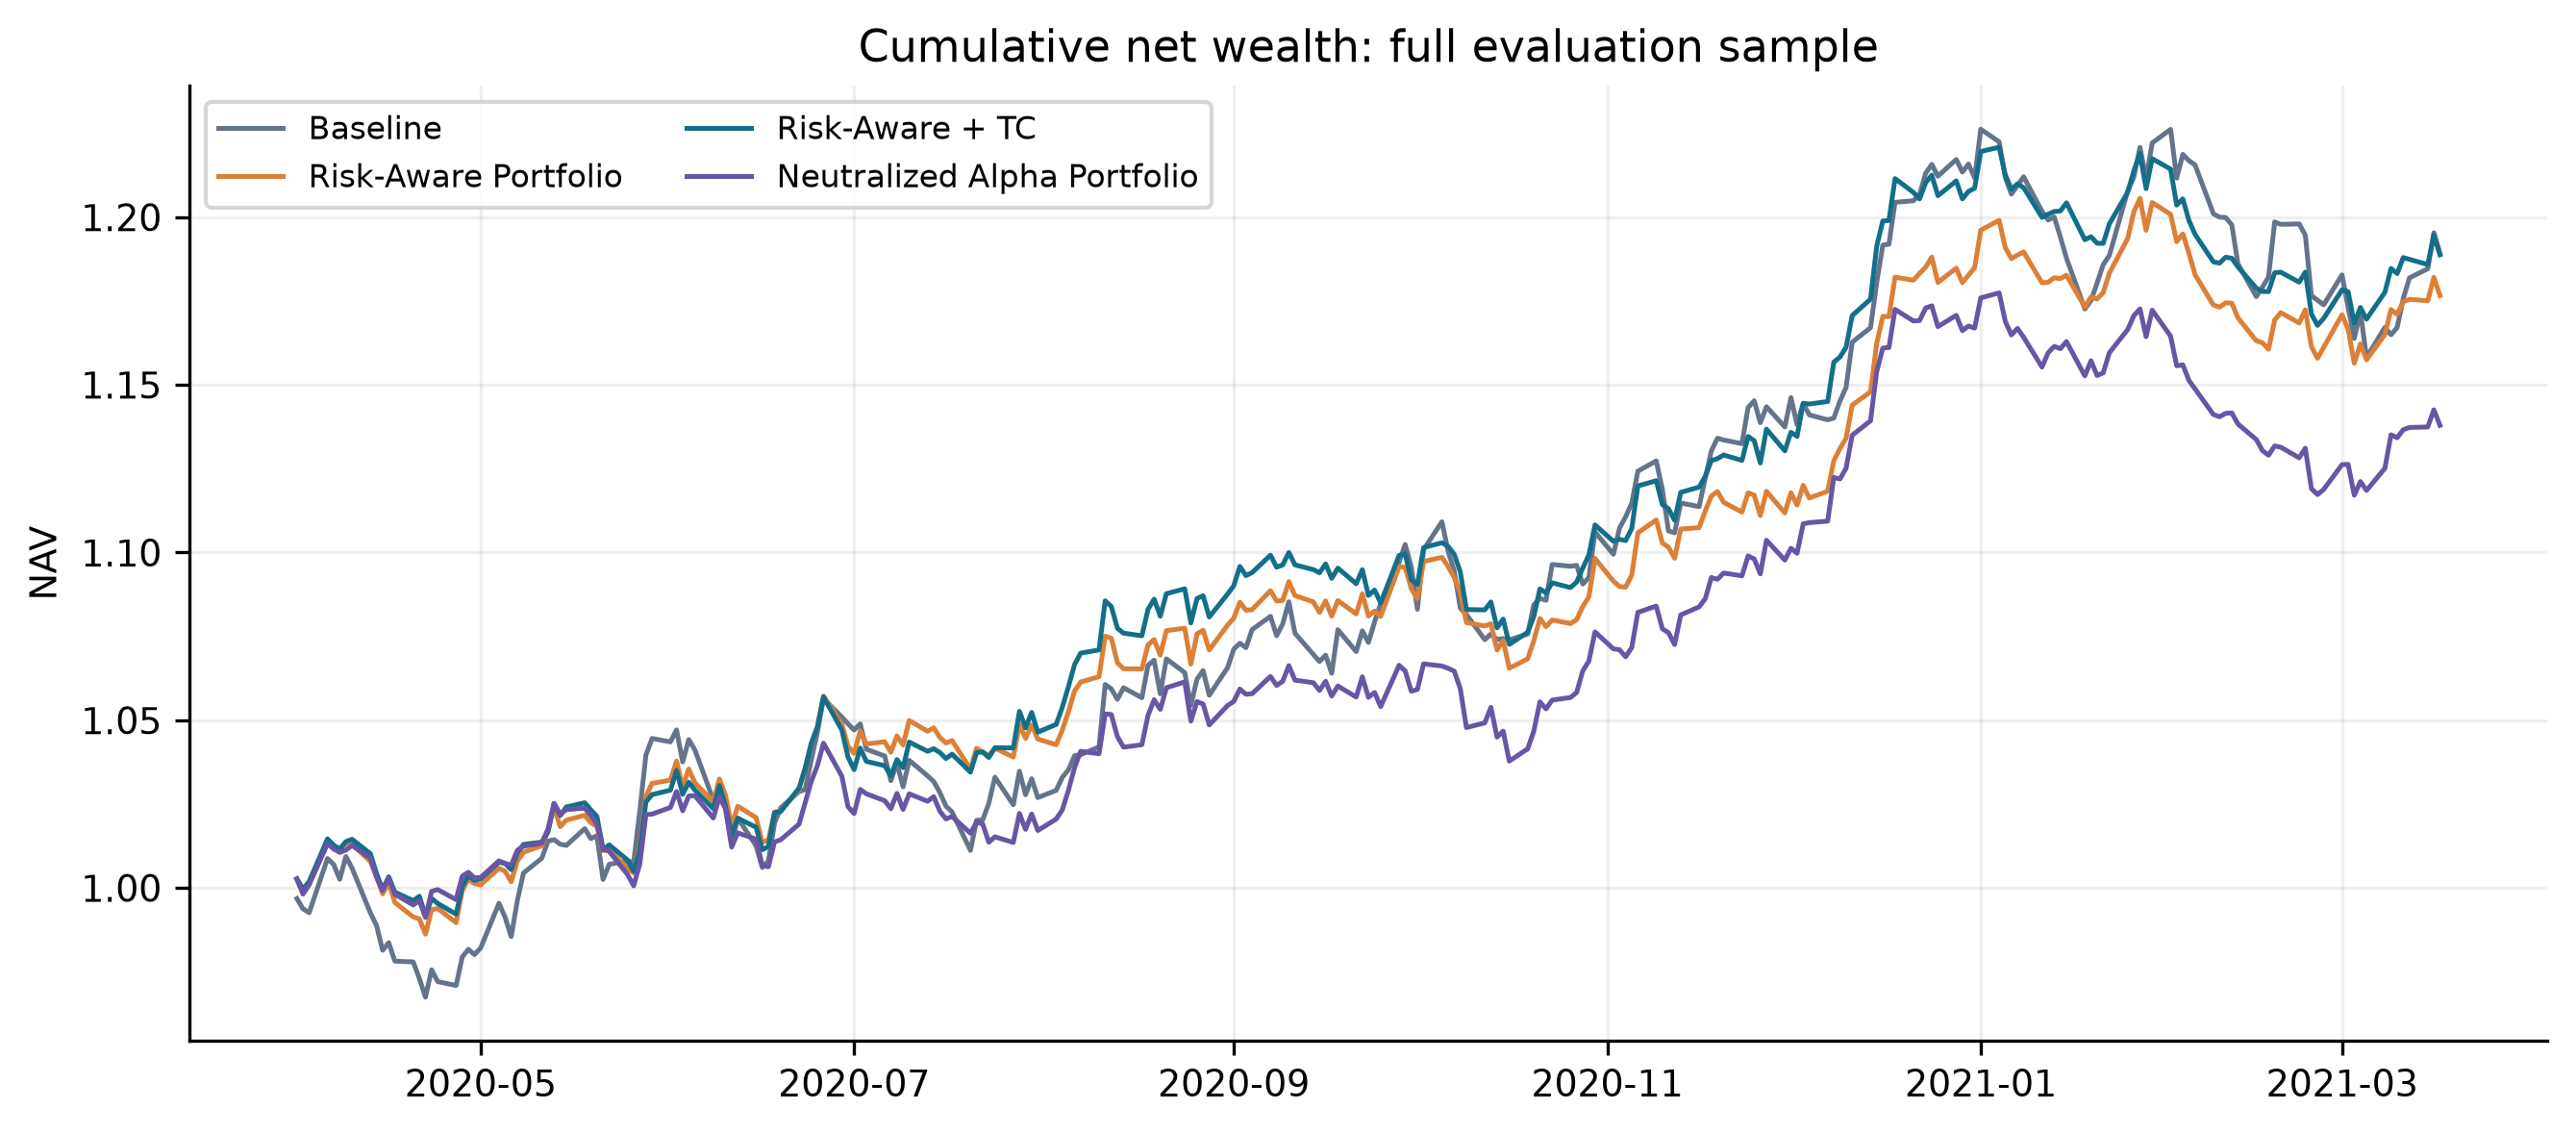

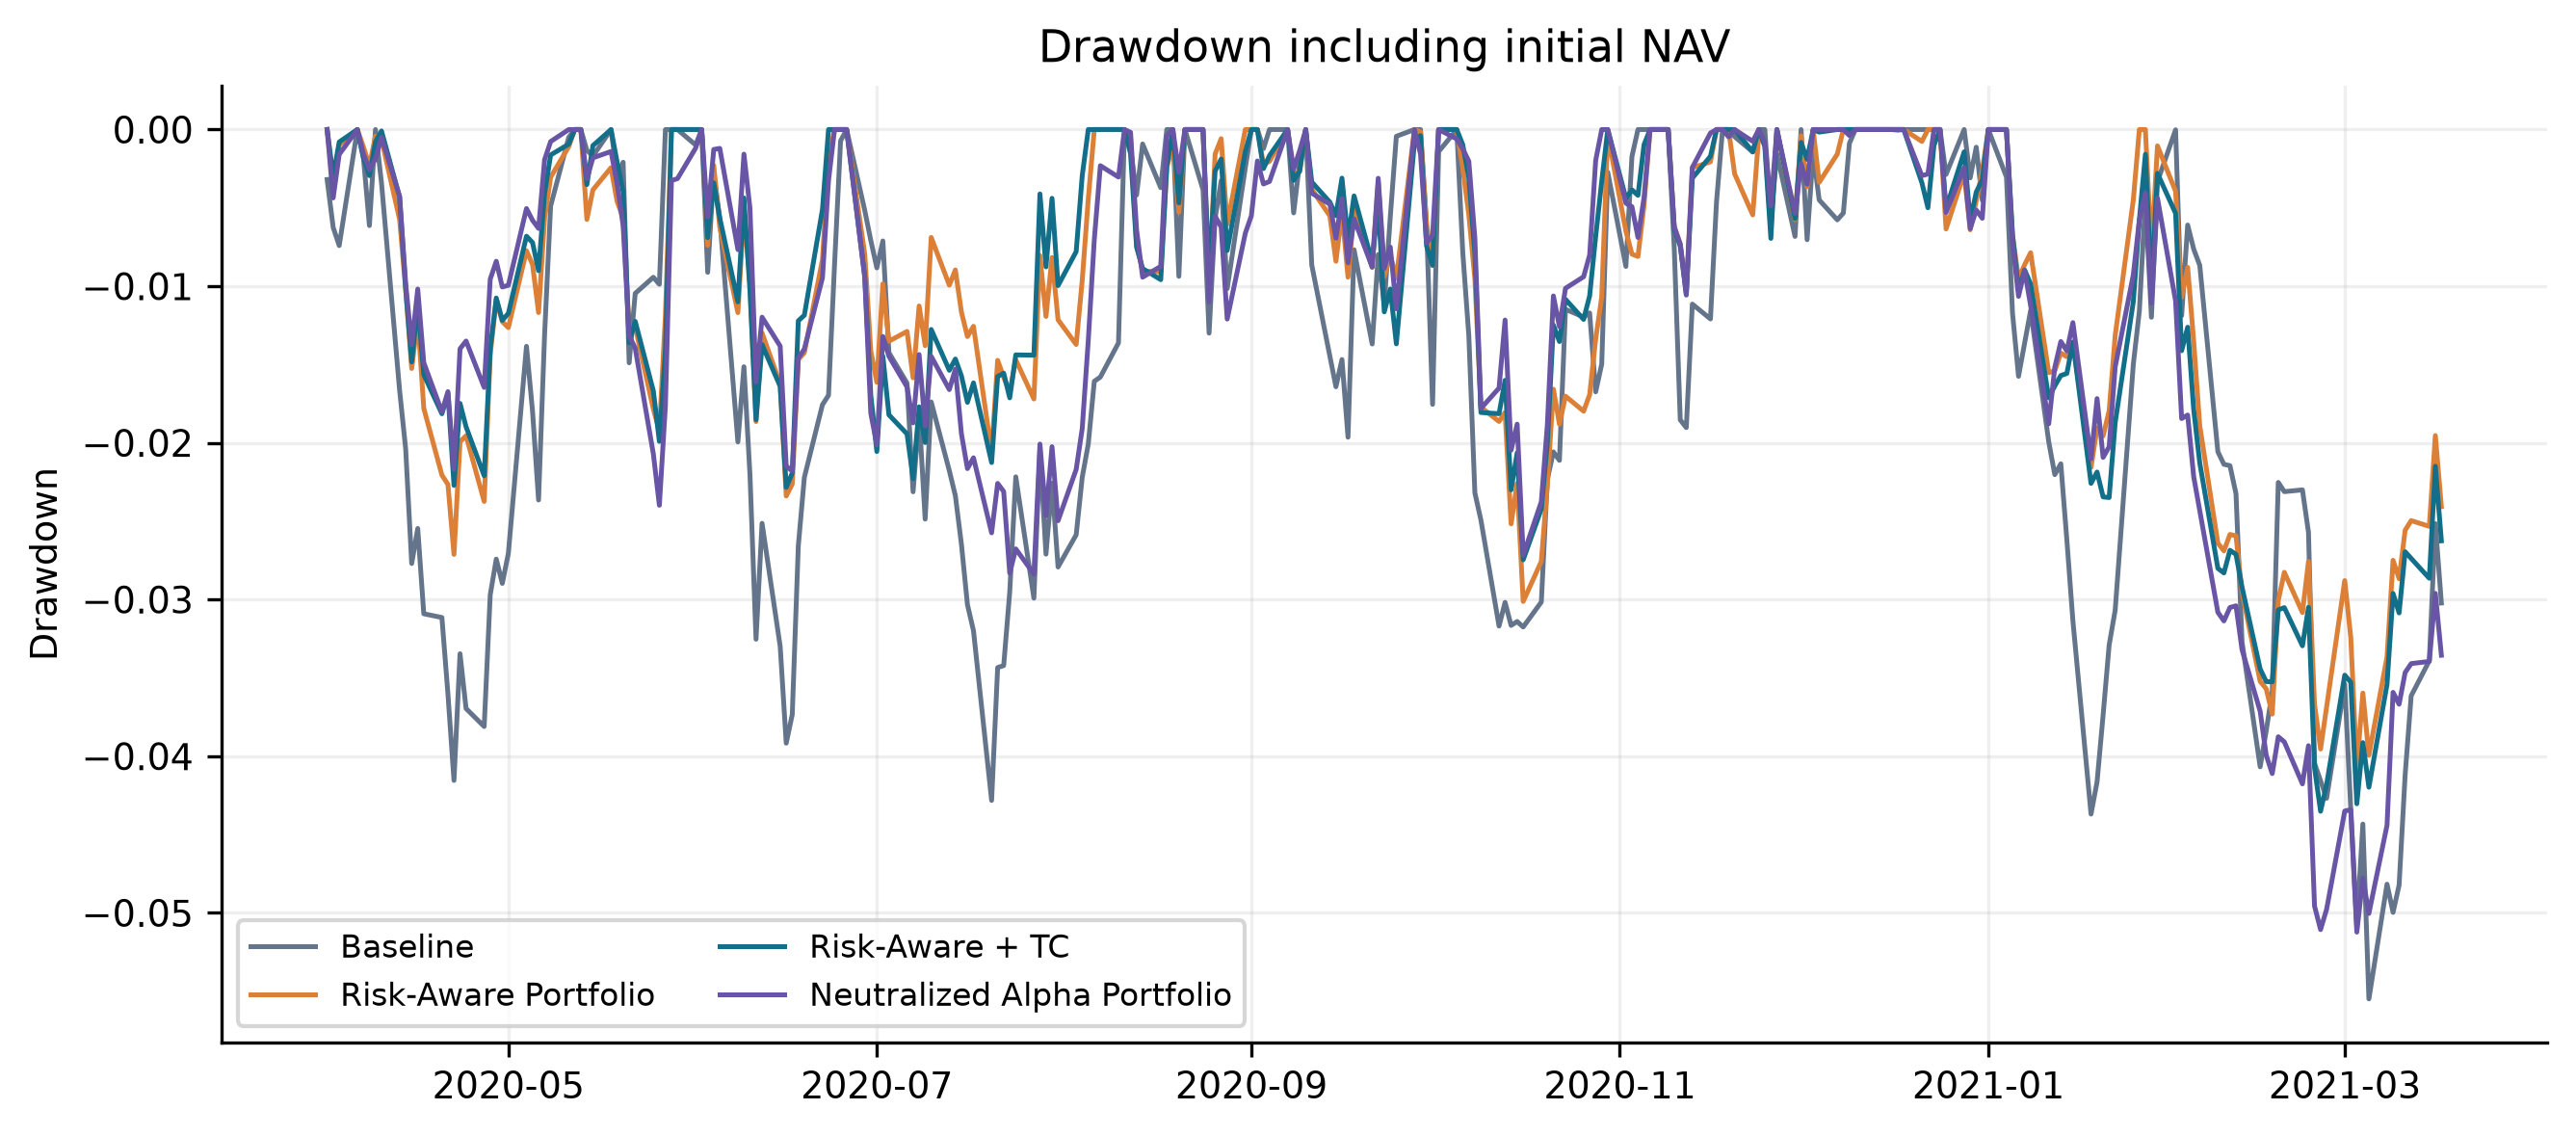

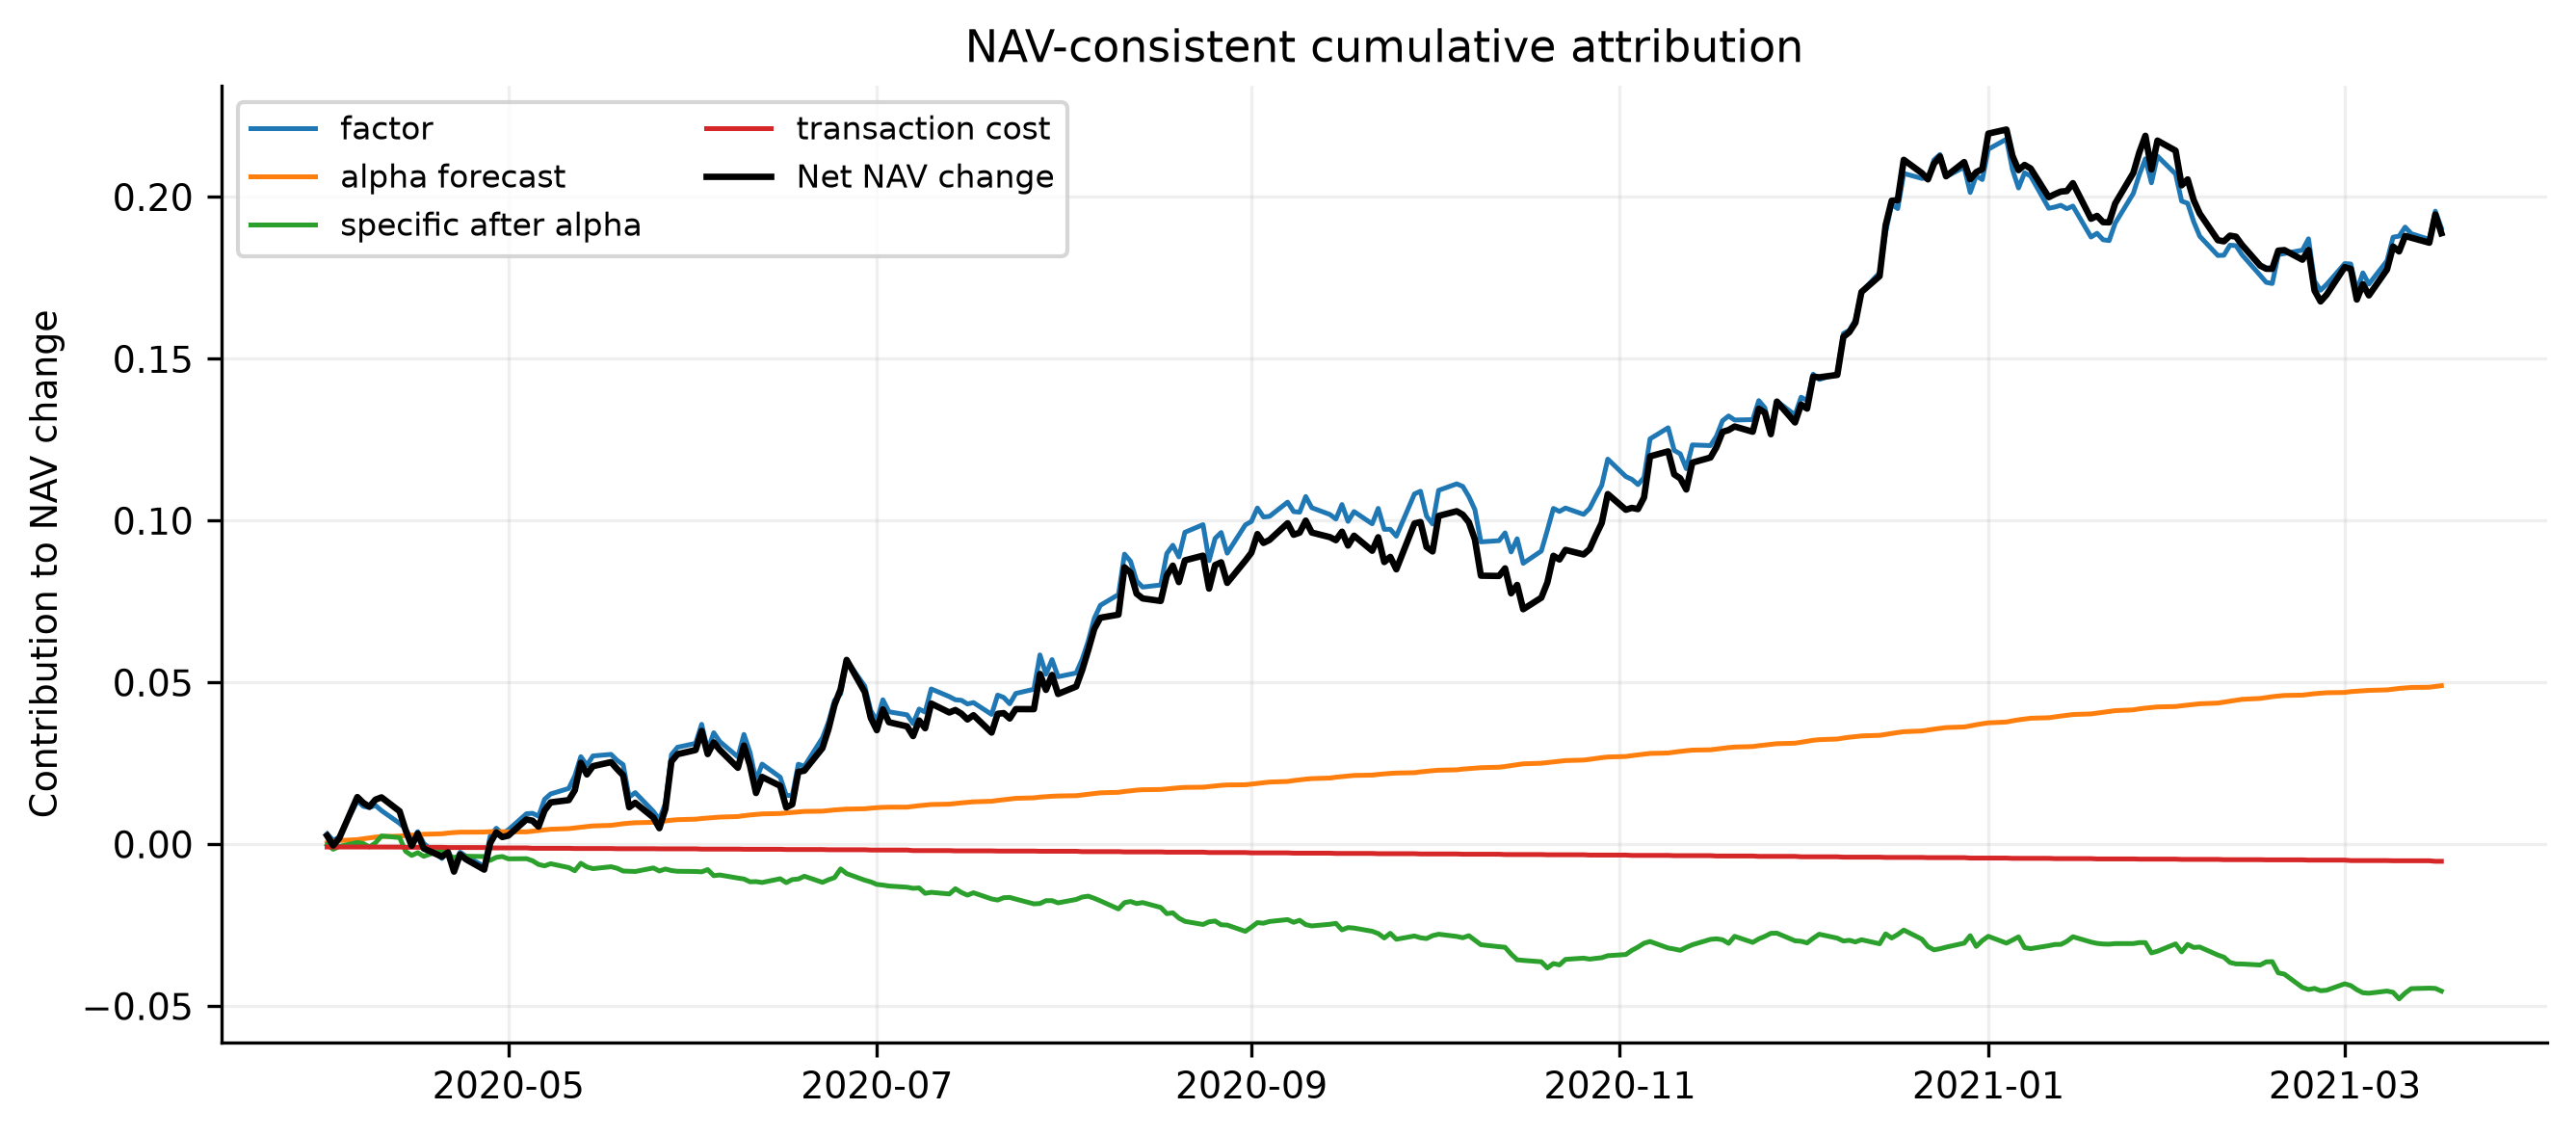

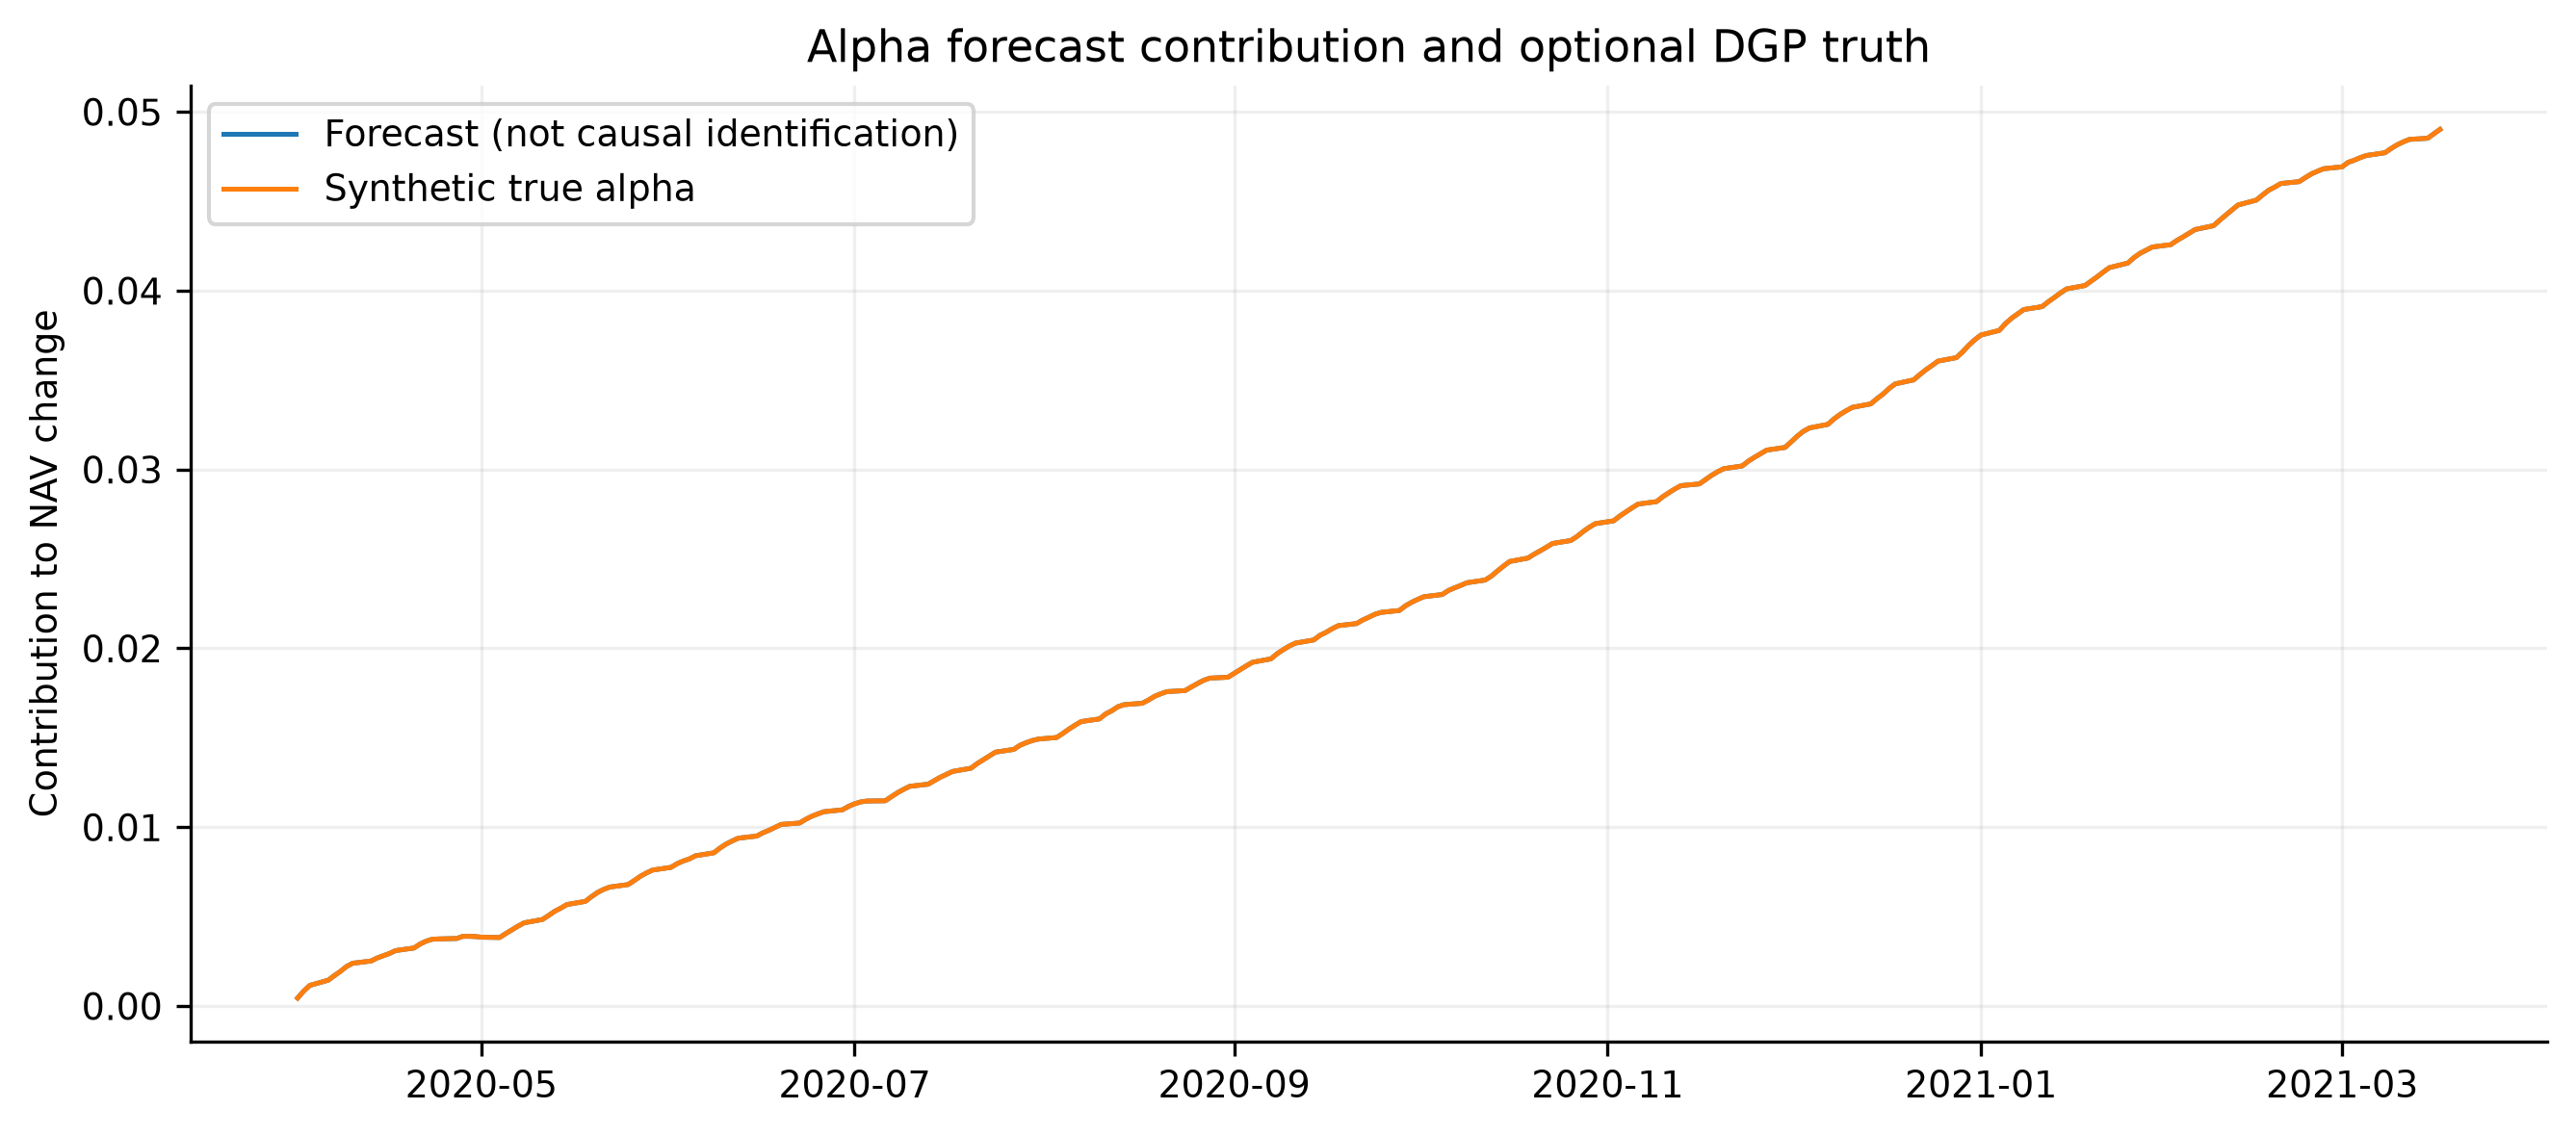

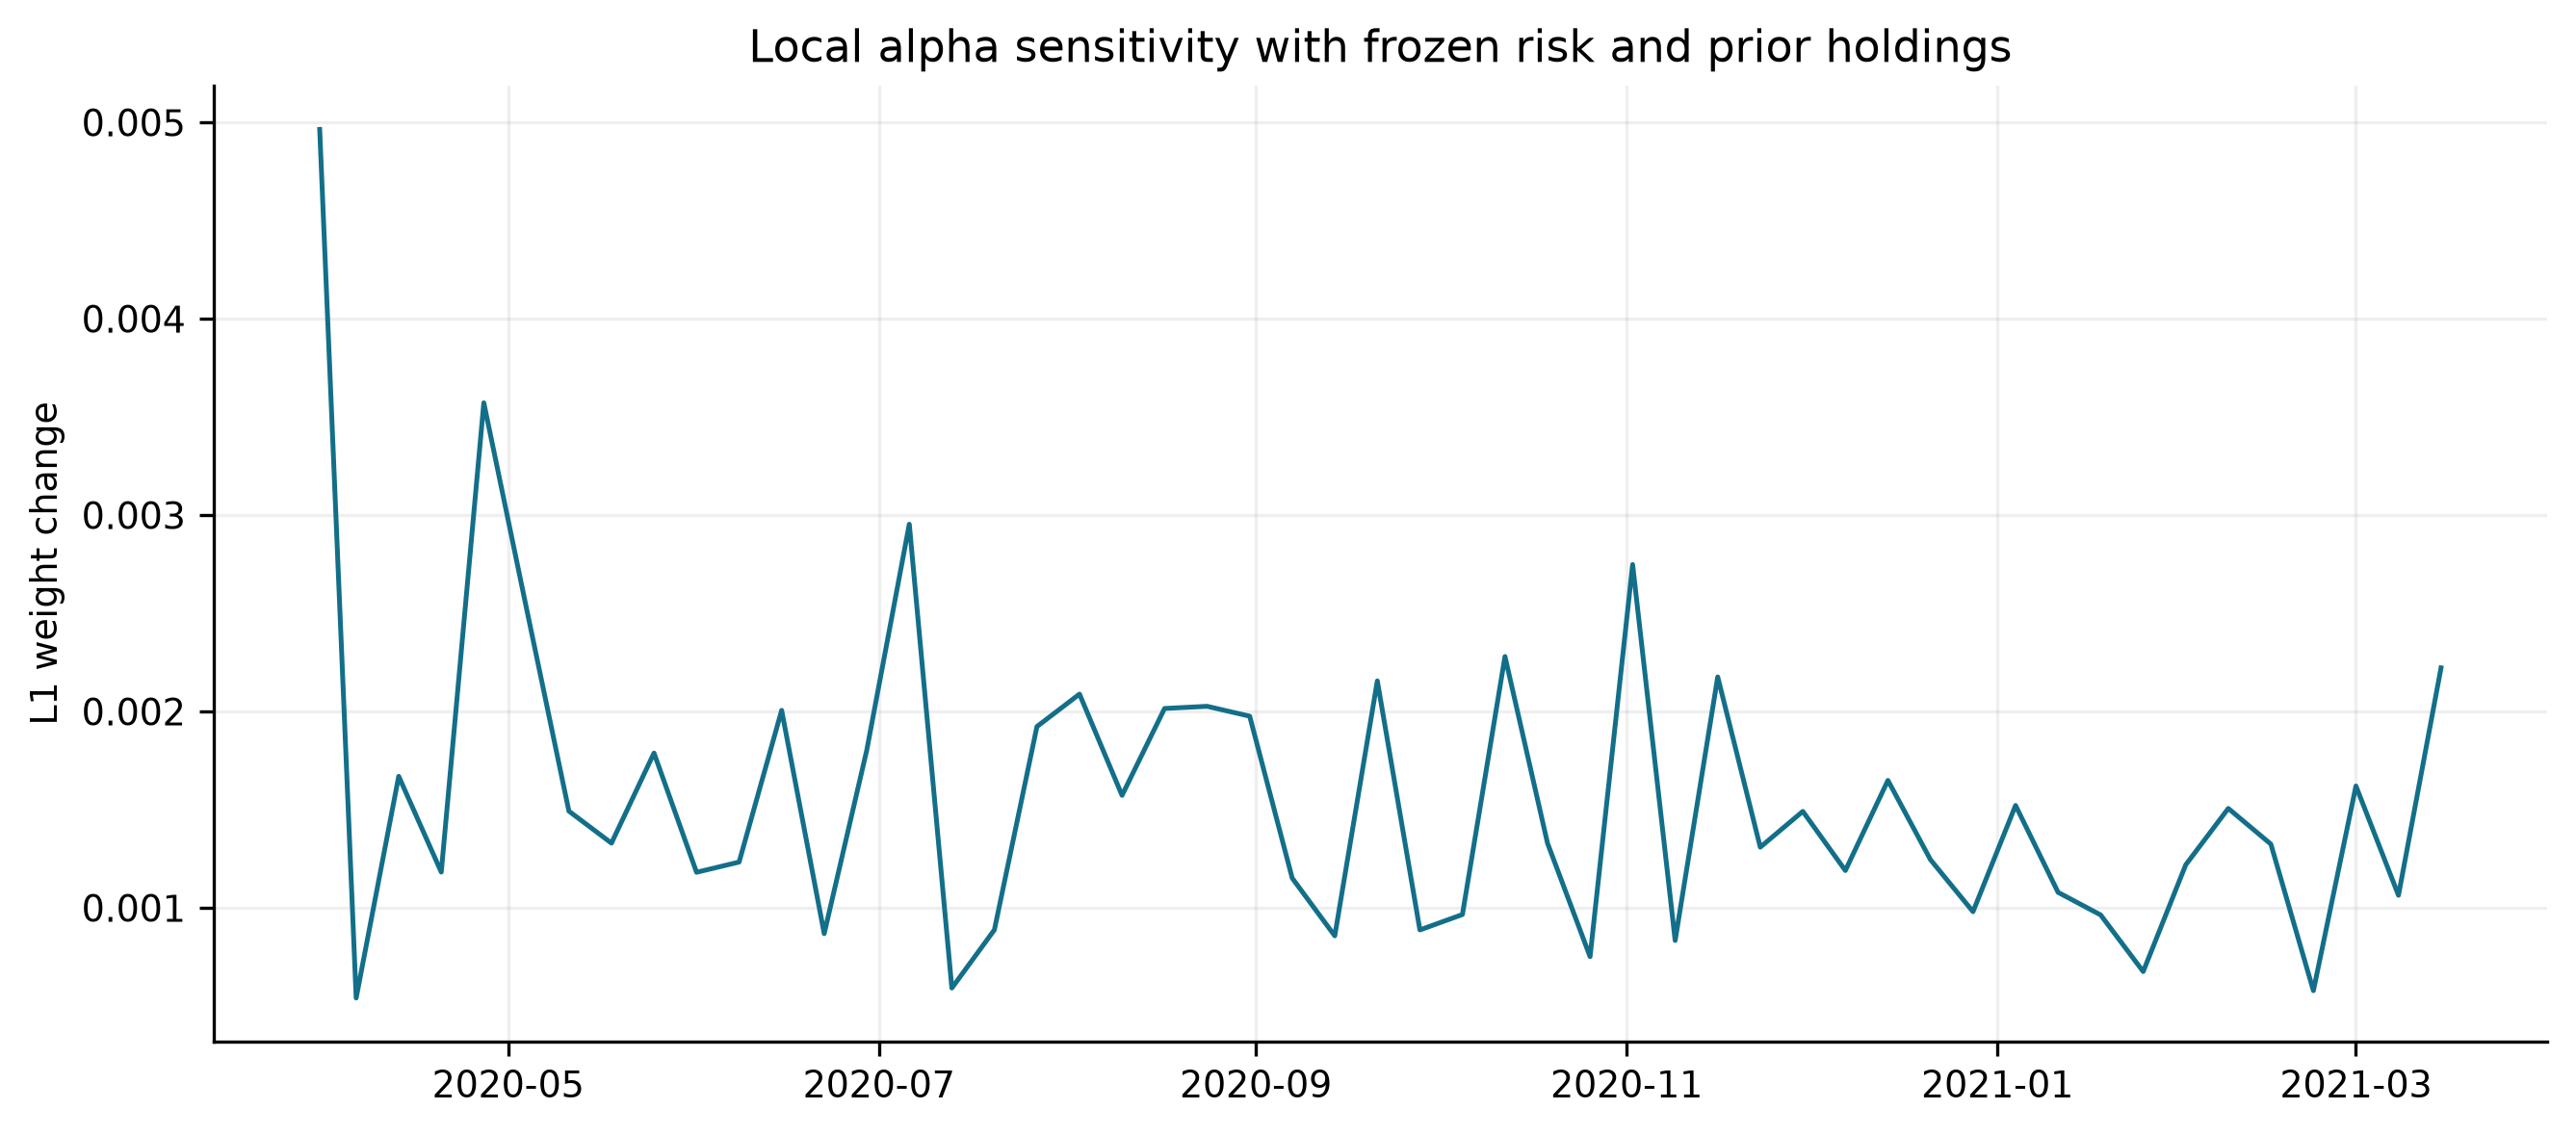

In [2]:
for name in ["cumulative_net_comparison", "drawdown", "factor_attribution", "alpha_attribution", "optimizer_stability"]:
    display(Image(filename=str(resolve_path(f"outputs/figures/{name}.png")), width=850))


## Interpretation limits

Factor + specific − cost is an accounting identity. Forecast alpha + residual-after-forecast is a labeled proxy split, not causal identification. Synthetic truth is stored separately and content-hash checked. Risk neutralization may remove predictive factor premia; optimization may amplify estimation errors; turnover and impact can reverse gross gains. No parameter setting is selected using these results. Real deployment needs point-in-time fundamentals, event handling, execution prices, borrow and funding costs, and capacity analysis.